In [ ]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from numpy.fft import rfft2, irfft2, rfft, irfft

base_dir = Path("solutions3.ipynb").resolve().parent
figures_dir = base_dir / "figures"
figures_dir.mkdir(exist_ok="True")
data_dir = base_dir / "data"

In [ ]:
plt.style.use("classic")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.family": "monospace",
    "font.monospace": ["DejaVu Sans Mono"],
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "axes.linewidth": 2.0,
    "axes.grid": False,
    "lines.color": "black",
    "lines.linewidth": 2.5,
    "xtick.color": "black",
    "ytick.color": "black",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "title_pad": 5,
})

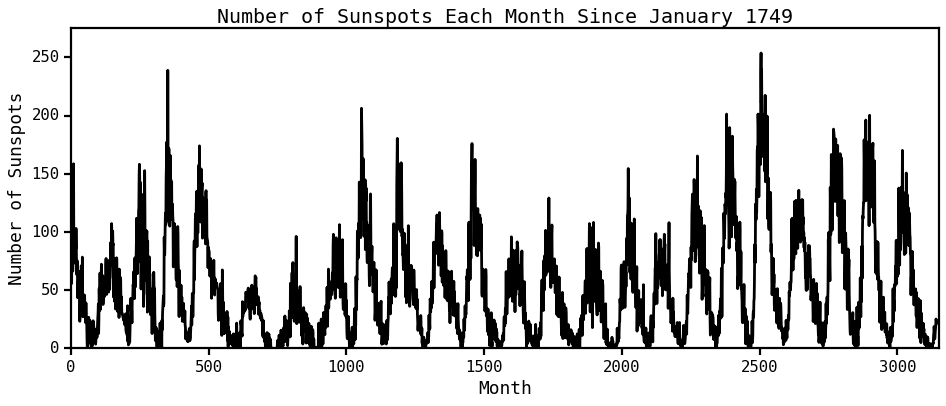

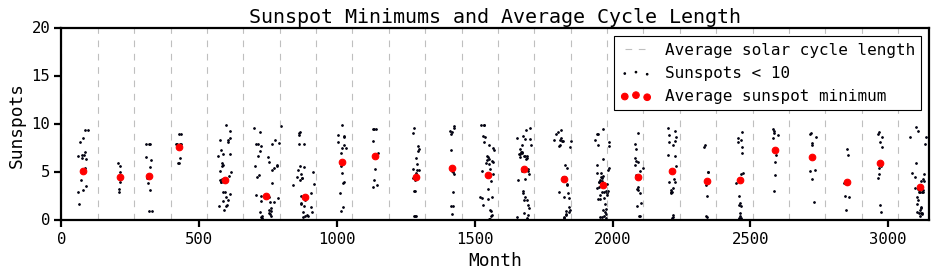

Estimated solar minimum months: [  76.63157895  210.85714286  317.75        426.77777778  593.45945946
  741.8         883.80434783 1018.41176471 1136.66666667 1286.08695652
 1418.35714286 1548.42857143 1680.13513514 1825.17142857 1963.91111111
 2091.84210526 2216.65217391 2341.125      2463.23529412 2588.6
 2725.11111111 2849.71428571 2970.36363636 3114.44117647]
Average solar cycle length: 132.07867815318346 months


In [247]:
# Newman 7.2: Detecting Periodicity

# (a)
sunspots = pd.read_csv(data_dir / "sunspots.txt", header=None, names=["month", "sunspot number"], sep=r'\s+')
months = sunspots["month"].values
sunspot_numbers = sunspots["sunspot number"].values

fig = plt.figure(figsize=(14,5))
plt.plot(months, sunspot_numbers, color="black")
plt.title("Number of Sunspots Each Month Since January 1749")
plt.tick_params(top=False, right=False, direction='out', length=6, width=2)
plt.xlabel("Month")
plt.ylabel("Number of Sunspots")
plt.ylim(0,275)
plt.xlim(0,3150)
plt.show()
fig.savefig(figures_dir / "sunspots.png", dpi=600, bbox_inches="tight")

# estimating the length of the cycle in months

fig, ax = plt.subplots(figsize=(14, 3))

solar_minimum_months = months[sunspot_numbers < 10]
solar_minimum_counts = sunspot_numbers[sunspot_numbers < 10]
split_indices = np.where(np.diff(solar_minimum_months) > 24)[0] + 1 # where the next clump starts
month_clumps = np.split(solar_minimum_months, split_indices)
count_clumps = np.split(solar_minimum_counts, split_indices)
minimum_months = np.array([np.mean(clump) for clump in month_clumps])
minimum_counts = np.array([np.mean(clump) for clump in count_clumps])

x_spots = np.arange(0, 3150, 132)
plt.vlines(x_spots, 0, 20, color="gray", alpha=0.5, linewidth=1, linestyle="--", label="Average solar cycle length")
plt.tick_params(top=False, right=False, direction='out', length=6, width=2)
ax.scatter(solar_minimum_months, solar_minimum_counts, s=2, label="Sunspots < 10")
ax.scatter(minimum_months, minimum_counts, s=35, color="red", label="Average sunspot minimum")
ax.set_xlim(0, 3150)
ax.set_ylim(0, 20)
ax.set_title("Sunspot Minimums and Average Cycle Length")
ax.set_xlabel("Month")
ax.set_ylabel("Sunspots")
ax.legend()
plt.show()
fig.savefig(figures_dir / "solar_minimums.png", dpi=600, bbox_inches="tight")

print("Estimated solar minimum months:", minimum_months)
print("Average solar cycle length:", np.mean(np.diff(minimum_months)), "months")

Peak k: 24
Peak power value: 2014337126.322072


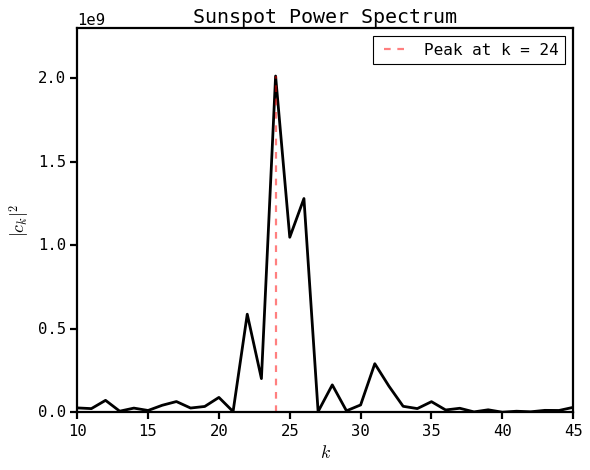

Peak frequency in cycles per month: 0.007636016544702513
Period in months: 130.95833333333334


In [246]:
# (b) 

from numpy import zeros
from cmath import exp,pi

N = len(sunspot_numbers)
c = np.fft.fft(sunspot_numbers)

k = np.arange(N//2 + 1)
c_selected = np.abs(c[:N//2 + 1])**2
mask = (k >=10) & (k <= 45)
masked_c = np.where(mask, c_selected, -np.inf)
k_peak = np.argmax(masked_c) 
peak_value = c_selected[k_peak]
print("Peak k:", k_peak)
print("Peak power value:", peak_value)

fig = plt.figure(figsize=(8,6))
plt.plot(c_selected, color="black")
plt.title("Sunspot Power Spectrum")
plt.ylabel(r"$|c_k|^2$")
plt.xlabel(r"$k$")
plt.xlim(10, 45)
plt.ylim(0, 2.3e9)
plt.tick_params(top=False, right=False, direction='out', length=6, width=2)
plt.vlines(k_peak, 0, peak_value, color="red", alpha=0.5, linewidth = 2, linestyle="--", label="Peak at k = {}".format(k_peak))
plt.legend()
plt.show()
fig.savefig(figures_dir / "sunspot_power_spectrum.png", dpi=600, bbox_inches="tight")

freq = np.fft.fftfreq(N, d=1)[:N//2 + 1]
freq_peak = freq[k_peak]
period = 1 / freq_peak
print("Peak frequency in cycles per month:", freq_peak)
print("Period in months:", period)

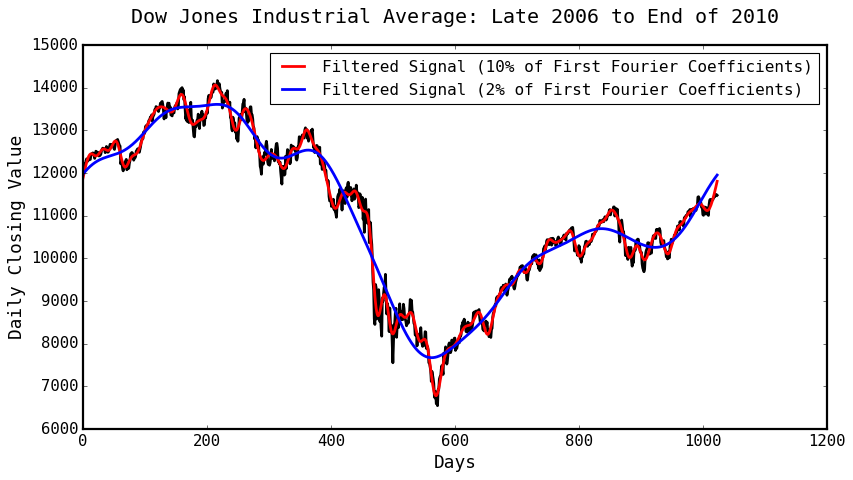

In [ ]:
# Newman 7.4

#(a)

dow = np.loadtxt(data_dir / "dow.txt")

# (b) calculate DFT using rfft

N = len(dow)
c = rfft(dow) # produces array of N//2 + 1 complex numbers

# (c) set all but the first 10% if elements of c to zero

y = c.copy()
y[int(0.1 * len(c)):] = 0

# (d) inverse ft 
x = irfft(y)

# (e) only keeping first 2% of the elements
y[int(0.02*len(c)):] = 0
z = irfft(y)

fig = plt.figure(figsize=(12,6))
plt.plot(dow, color = "black")
plt.plot(x, color = "red", label = "Filtered Signal (10% of First Fourier Coefficients)")
plt.plot(z, color = "blue", label = "Filtered Signal (2% of First Fourier Coefficients)")
plt.title("Dow Jones Industrial Average: Late 2006 to End of 2010", pad=20)
plt.xlabel("Days")
plt.ylabel("Daily Closing Value")
plt.legend()
plt.show()
fig.savefig(figures_dir / "dow.png", dpi=600, bbox_inches="tight")


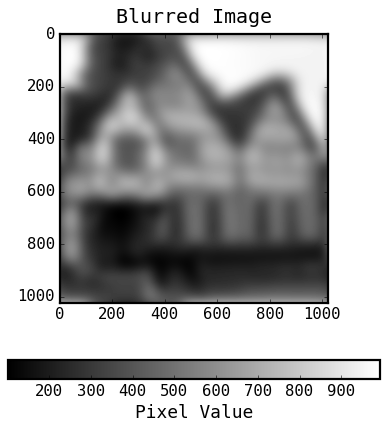

(1024, 1024)


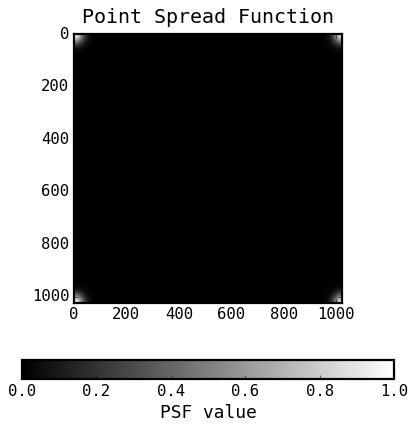

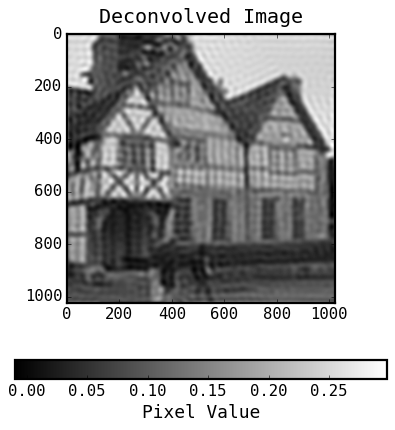

In [356]:
# Newman 7.9: Image Deconvolution

#(a)

blur = np.loadtxt(data_dir / "blur.txt")
fig = plt.figure(figsize=(6,6))
plt.imshow(blur, cmap="gray")
plt.title("Blurred Image", pad=10)
plt.colorbar(label="Pixel Value", orientation="horizontal")
plt.show()
fig.savefig(figures_dir / "blur.png", dpi=600, bbox_inches="tight")
print(blur.shape)

#(b)

ny, nx = blur.shape
sigma = 25

def f(x, y): # we need periodic coords
    x = np.where(x <= nx // 2, x, x - nx)
    y = np.where(y <= ny // 2, y, y - ny)
    return np.exp(-(x**2 + y**2) / (2 * sigma**2))

point_spread = np.fromfunction(f, blur.shape)

fig = plt.figure(figsize=(6, 6))
plt.imshow(point_spread, cmap="gray")
plt.title("Point Spread Function", pad=10)
plt.colorbar(label="PSF value", orientation="horizontal")
plt.show()
fig.savefig(figures_dir / "point_spread.png", dpi=600, bbox_inches="tight")

# (c)

blur_fft = rfft2(blur)
psf_fft = rfft2(point_spread)

# accounting for division by zero
epsilon = 1e-3
deconvolved_fft = blur_fft.copy()
mask = np.abs(psf_fft) >= epsilon
deconvolved_fft[mask] = blur_fft[mask] / psf_fft[mask]
deconvolved = np.fft.irfft2(deconvolved_fft, s=blur.shape)

fig = plt.figure(figsize=(6, 6))
plt.imshow(deconvolved, cmap="gray")
plt.title("Deconvolved Image", pad=10)
plt.colorbar(label="Pixel Value", orientation="horizontal")
plt.show()
fig.savefig(figures_dir / "deconvolved.png", dpi=600, bbox_inches="tight")


